# 2ACDC_CL analysis

Plots and comparisons for 2ACDC_CL models exported by `optimize/nested_optimize_EIANN_2ACDC_CL.py`. The tracks are shown in blocks (`AlternatingSchedule`): `episodes_per_task` episodes of track 1, then of track 2, for `num_cycles` cycles. Only the continual-learning plots are here; for the standard plots of one seed, use `nested.analyze --plot` or `plot_2ACDC_summary`. Everything works from the laps saved in each pickle, so nothing here retrains.

Export a model with, from the `EIANN` package directory:

```bash
mkdir -p data/2ACDC_CL
python -m nested.analyze --framework=serial --config-file-path=<optimize config> \
  --param-file-path=optimize/optimize_params/2ACDC_CL/20261103_2ACDC_CL_params.yaml --model-key=<key> \
  --output-dir=data/2ACDC_CL --label=<key> --num_instances=5 --export --disp
```

For more blocks than were optimized, add e.g. `--num_cycles=4` and use a different `--label` (exports are not overwritten), then add that label to `models` below.

In [1]:
import glob
import os

import matplotlib.pyplot as plt
import numpy as np

import EIANN.utils as ut
from EIANN.plot import clean_axes, update_plot_defaults
from EIANN.reinforcement_learning.environments import make_2ACDC_tracks
from EIANN.reinforcement_learning.treadmill_metrics import (stack_laps, licks_by_zone, block_rewards,
                                                            seen_track_rewards)
from EIANN.reinforcement_learning.treadmill_plots import SERIES_COLORS, mark_blocks, plot_hidden_activity

%matplotlib inline
update_plot_defaults()

# tracks keep SERIES_COLORS[0] and [1] (as in the block shading), so models use the next colors
MODEL_COLORS = SERIES_COLORS[2:]

## Load models

In [2]:
data_dir = '../data/2ACDC_CL'
num_episodes_reward_window = 100  # as in the optimize configs: phase rewards average the last episodes of each block

# model name: (network config name, nested label)
models = {'van_bp': ('20261103_EIANN_2_hidden_2ACDC_CL_van_bp_relu_SGD_config', 'van_bp_relu_SGD'),
          'eprop': ('20261103_EIANN_2_hidden_2ACDC_CL_eprop_relu_SGD_config', 'eprop_relu_SGD'),
          'van_bp_SI': ('20261103_EIANN_2_hidden_2ACDC_CL_van_bp_SI_relu_SGD_config', 'van_bp_SI_relu_SGD'),
          'van_bp_EWC': ('20261103_EIANN_2_hidden_2ACDC_CL_van_bp_EWC_relu_SGD_config', 'van_bp_EWC_relu_SGD')}


def load_rl_histories(network_name, label):
    """
    The rl_history of every exported seed of a model, by '<seed>_<data_seed>'.
    """
    histories = {}
    for path in sorted(glob.glob(f'{data_dir}/{network_name}/{network_name}_*_{label}.pkl')):
        seed = os.path.basename(path)[len(network_name) + 1:-len(label) - 5]
        histories[seed] = ut.load_network(path, disp=False).rl_history
    return histories


histories = {name: load_rl_histories(*model) for name, model in models.items()}
# models without exported pickles are left out of the plots
missing = [name for name, model_histories in histories.items() if not model_histories]
histories = {name: model_histories for name, model_histories in histories.items() if model_histories}
print('not exported yet:', missing)
{name: list(model_histories) for name, model_histories in histories.items()}

not exported yet: ['van_bp_SI', 'van_bp_EWC']


{'van_bp': ['66049_257', '66050_258', '66051_259', '66053_261'],
 'eprop': ['66049_257', '66050_258', '66051_259', '66052_260', '66053_261']}

## Phase rewards (the optimization objectives)

As in class-incremental MNIST with a cumulative val set: `phase{b}_reward` is the greedy reward averaged over the tracks seen so far, over the last `num_episodes_reward_window` episodes of block b. The reward matrix holds every track at the end of every block (rows: block and the track it trains on; columns: track evaluated). Mean ± SEM over seeds.

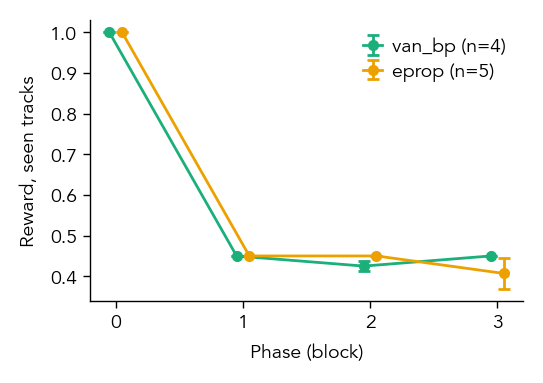

{'van_bp': [1.0, 0.45, 0.425, 0.45], 'eprop': [1.0, 0.45, 0.45, 0.407]}

In [3]:
def get_track_rewards(history):
    """
    Greedy reward of every track at every validation step, shape (num_val, num_tracks).
    """
    return np.array([[lap['episode_return'] for lap in laps] for laps in history['val_laps']])


def get_reward_matrix(history):
    num_blocks = history['num_tracks'] * history['num_cycles']
    return block_rewards(get_track_rewards(history), history['val_episodes'], history['episodes_per_task'],
                         num_blocks, num_episodes_reward_window)


reward_matrices = {name: np.array([get_reward_matrix(history) for history in model_histories.values()])
                   for name, model_histories in histories.items()}
phase_rewards = {name: np.array([seen_track_rewards(matrix) for matrix in matrices])
                 for name, matrices in reward_matrices.items()}

fig, ax = plt.subplots(figsize=(2.6, 1.8), layout='constrained')
for i, ((name, rewards), color) in enumerate(zip(phase_rewards.items(), MODEL_COLORS)):
    phases = np.arange(rewards.shape[1]) + 0.1 * (i - (len(phase_rewards) - 1) / 2)
    ax.errorbar(phases, rewards.mean(axis=0), yerr=rewards.std(axis=0) / np.sqrt(len(rewards)), color=color,
                marker='o', markersize=3, linewidth=1, capsize=2, label=f'{name} (n={len(rewards)})')
ax.set_xticks(range(rewards.shape[1]))
ax.set_xlabel('Phase (block)')
ax.set_ylabel('Reward, seen tracks')
ax.legend()
clean_axes(ax)
plt.show()

{name: np.round(rewards.mean(axis=0), 3).tolist() for name, rewards in phase_rewards.items()}

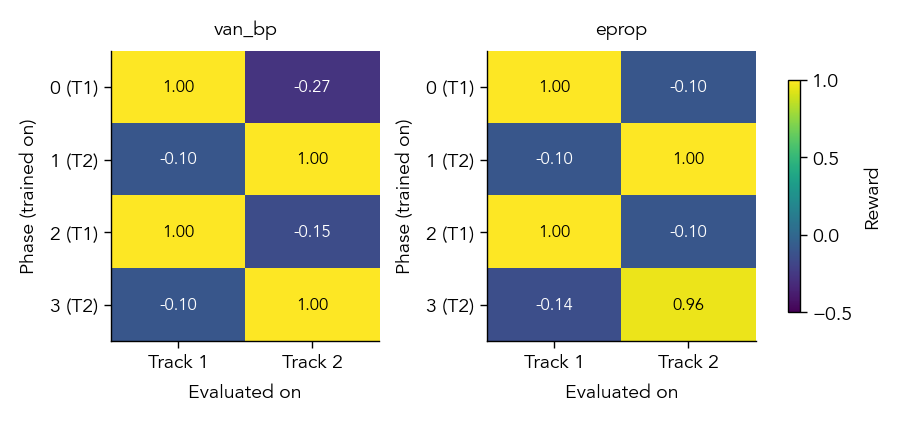

In [4]:
fig, axes = plt.subplots(1, len(reward_matrices), figsize=(2.2 * len(reward_matrices), 2.), layout='constrained')
for ax, (name, matrices) in zip(np.atleast_1d(axes), reward_matrices.items()):
    matrix = matrices.mean(axis=0)
    num_blocks, num_tracks = matrix.shape
    image = ax.imshow(matrix, cmap='viridis', vmin=-0.5, vmax=1., aspect='auto')
    for block in range(num_blocks):
        for track in range(num_tracks):
            ax.text(track, block, f'{matrix[block, track]:.2f}', ha='center', va='center', fontsize=6,
                    color='white' if matrix[block, track] < 0.5 else 'black')
    ax.set_xticks(range(num_tracks), [f'Track {track + 1}' for track in range(num_tracks)])
    ax.set_yticks(range(num_blocks), [f'{block} (T{block % num_tracks + 1})' for block in range(num_blocks)])
    ax.set_xlabel('Evaluated on')
    ax.set_ylabel('Phase (trained on)')
    ax.set_title(name)
fig.colorbar(image, ax=axes, label='Reward', shrink=0.8)
plt.show()

## Compare models over training

Reward on each track over training (mean ± SEM over seeds), with blocks shaded by the track they train on.

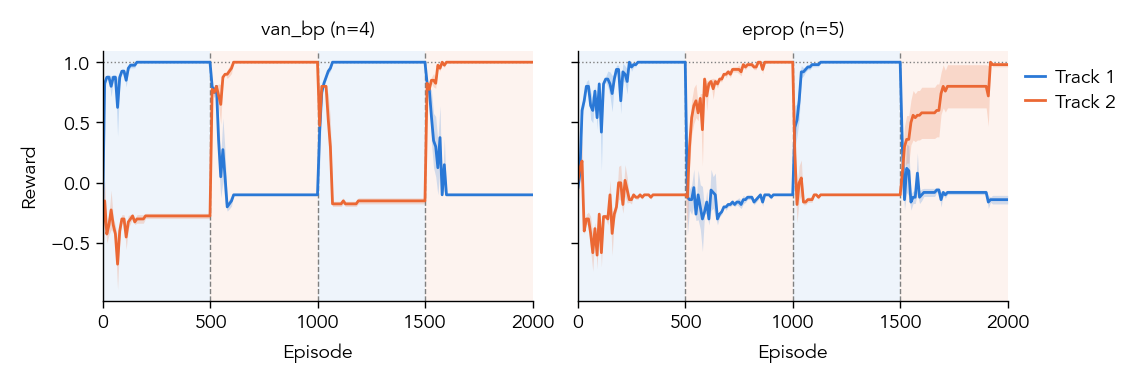

In [5]:
def plot_mean_sem(ax, episodes, values, color, label=None):
    mean, sem = values.mean(axis=0), values.std(axis=0) / np.sqrt(len(values))
    ax.plot(episodes, mean, color=color, linewidth=1, label=label)
    ax.fill_between(episodes, mean - sem, mean + sem, color=color, alpha=0.2, linewidth=0)


fig, axes = plt.subplots(1, len(histories), figsize=(2.8 * len(histories), 1.8), sharey=True, layout='constrained')
for ax, (name, model_histories) in zip(np.atleast_1d(axes), histories.items()):
    first = next(iter(model_histories.values()))
    episodes = first['val_episodes']
    track_rewards = np.array([get_track_rewards(history) for history in model_histories.values()])
    mark_blocks(ax, episodes, first['episodes_per_task'], first['num_tracks'])
    ax.axhline(1., color='gray', linestyle=':', linewidth=0.5)
    for track in range(first['num_tracks']):
        plot_mean_sem(ax, episodes, track_rewards[:, :, track], SERIES_COLORS[track], label=f'Track {track + 1}')
    ax.set_title(f'{name} (n={len(track_rewards)})')
    ax.set_xlabel('Episode')
np.atleast_1d(axes)[0].set_ylabel('Reward')
np.atleast_1d(axes)[-1].legend(frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
clean_axes(axes)
plt.show()

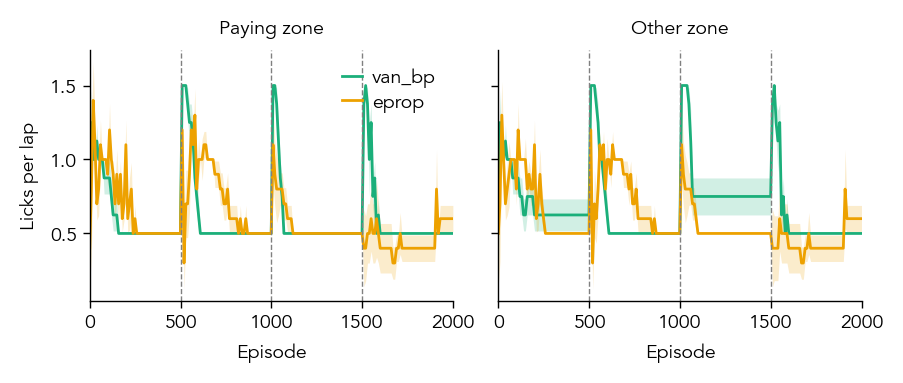

In [6]:
def get_zone_licks(history):
    """
    Mean number of licks per track in the zone that pays on that track, and in the zone that doesn't, over training.
    """
    laps = stack_laps(history['val_laps'], history['val_episodes'])
    licks = licks_by_zone(laps, make_2ACDC_tracks(**history['treadmill_kwargs'])[0])
    correct = licks.diagonal(axis1=1, axis2=2).mean(axis=1)
    wrong = licks.sum(axis=(1, 2)) / licks.shape[1] - correct
    return correct, wrong


fig, axes = plt.subplots(1, 2, figsize=(4.4, 1.8), sharey=True, layout='constrained')
for (name, model_histories), color in zip(histories.items(), MODEL_COLORS):
    first = next(iter(model_histories.values()))
    zone_licks = np.array([get_zone_licks(history) for history in model_histories.values()])
    plot_mean_sem(axes[0], first['val_episodes'], zone_licks[:, 0], color, label=name)
    plot_mean_sem(axes[1], first['val_episodes'], zone_licks[:, 1], color)
for ax in axes:
    mark_blocks(ax, first['val_episodes'], first['episodes_per_task'], first['num_tracks'], shade=False)
    ax.set_xlabel('Episode')
axes[0].set_title('Paying zone')
axes[1].set_title('Other zone')
axes[0].set_ylabel('Licks per lap')
axes[0].legend()
clean_axes(axes)
plt.show()

## Individual plots

Each plot function takes `laps` and `tracks`, so any of them can be called on its own, for example hidden activity at the end of every block.

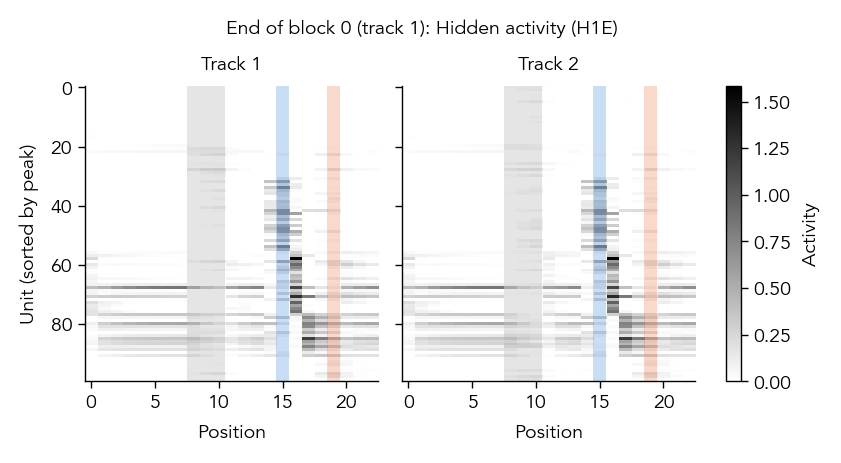

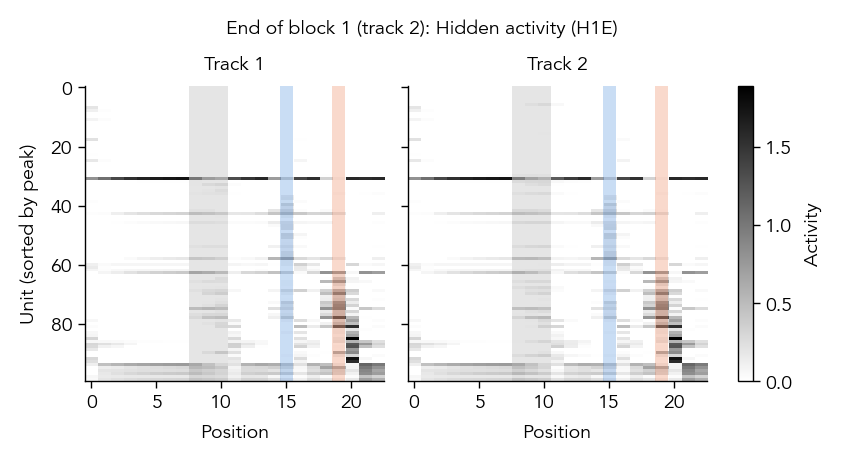

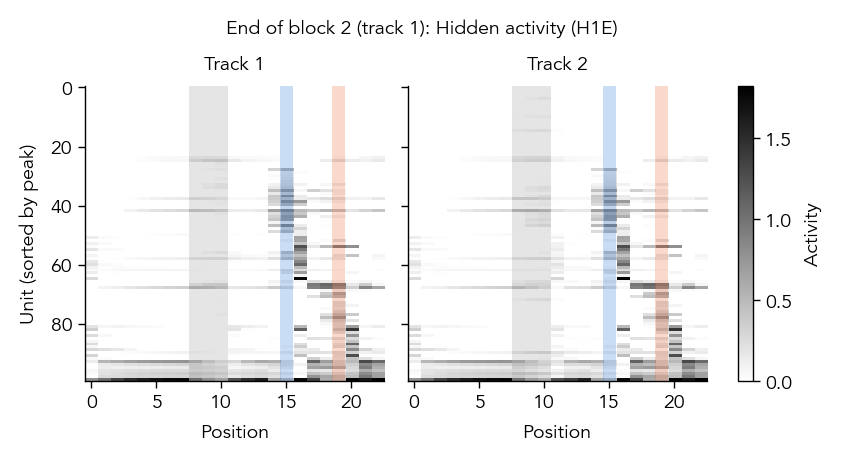

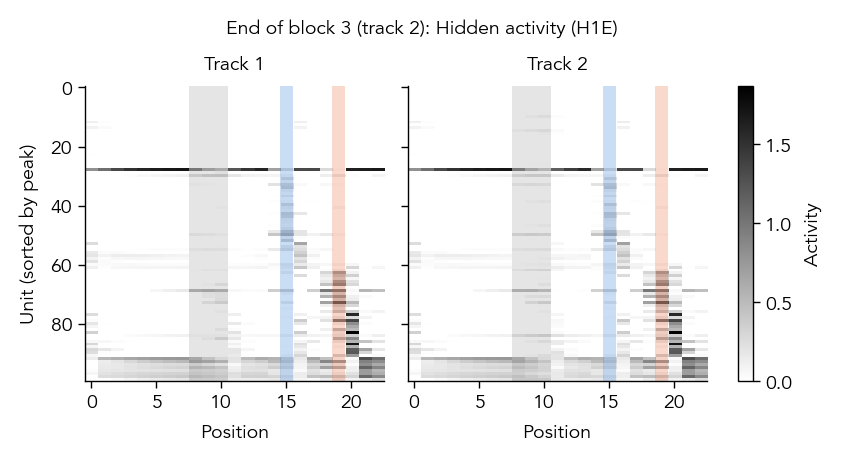

In [7]:
model, seed = 'eprop', '66049_257'
history = histories[model][seed]
laps = stack_laps(history['val_laps'], history['val_episodes'])
tracks = make_2ACDC_tracks(**history['treadmill_kwargs'])
num_blocks = history['num_tracks'] * history['num_cycles']
for block in range(num_blocks):
    # last validation step of the block
    val_step = np.searchsorted(laps['episodes'], (block + 1) * history['episodes_per_task'] - 1, side='right') - 1
    plot_hidden_activity(laps, tracks, populations=['H1E'], val_step=val_step,
                         title=f'End of block {block} (track {block % history["num_tracks"] + 1})')